# Лабораторная работа №2. Вывод символов на экран дисплея.

**Выполнил:** Рулев Константин Александрович

**Вариант:** 16

Рабочее окружение: GitHub Codespaces (Ubuntu, x86-64), ассемблер `fasm`, компоновщик `ld`, компилятор `gcc`.

Программы написаны в стиле лекции 2: формат `ELF64`, секции `.data`/`.bss`/`.text`, системные вызовы `sys_write` (`eax = 4`) и `sys_exit` (`eax = 1`) через `int 0x80`, вывод оформлен подпрограммами `print`, `print_symb`, `newline` и `exit`.

## Исходные данные варианта

Параметры получены генератором из методических указаний при `Variant = 16`.

In [ ]:
import random as rd
import pandas as pd
import math

Variant = 16
rd.seed(Variant)
Str1 = 'qwertyuioplkjhgfdsazxcvbnmQWERTYUIOPASDFGHJKLZXCVBNM'
N = rd.randint(20,40)
s1 = ''
for i in range(N):
    s1 += Str1[rd.randint(0, len(Str1)-1)]
D = '!@#$%&*+:;|'[rd.randint(0,10)]
N1 = rd.randint(3,30)
N2 = int(N1 * (N1 + 1) / 2)
if (int(N2/N1) - math.floor(N2/N1)) == 0:
    M = int(N2 / N1)
    K = int(N2 / M)
else:
    M = int(N2 / (N1 + 1))
    K = int(N2 / M)
N4 = rd.randint(123432, 5645634534)
Data  = pd.DataFrame({'Задание':[1,2,3,4,5],'Параметры':['S='+s1,[D, 'N='+str(N2), 
                    'M ='+str(M), 'K = '+str(K)],'-','N='+str(N4),'-']})
Data

   Задание                             Параметры
0        1     S=TTaQgEqQJZdfGgqazcJpCDzwNgDdwpM
1        2               [;, N=300, M =12, K = 25]
2        3                                     -
3        4                          N=2710058798
4        5                                     -


| Задание | Параметры |
|---|---|
| 1 | S = `TTaQgEqQJZdfGgqazcJpCDzwNgDdwpM` (31 символ) |
| 2 | символ `;`, N = 300, M = 12, K = 25 |
| 3 | те же 300 символов `;` в виде треугольника (1 + 2 + … + 24 = 300) |
| 4 | N = 2710058798 |
| 5 | то же число на языке C, сравнение размеров исполняемых файлов |

## Задание 1. Вывод строки S в обратном порядке

Строка хранится в секции данных, её длину вычисляет ассемблер (`S_len = $ - S`). Сначала выводится исходная строка, затем строка переворачивается прямо в памяти: регистр `rsi` указывает на первый байт, `rdi` — на последний, байты меняются местами, указатели сдвигаются навстречу друг другу, пока не встретятся (`cmp rsi, rdi` / `jae`). После этого перевёрнутая строка выводится одним системным вызовом `sys_write`.

In [ ]:
%%writefile task1_reverse.asm
; Лабораторная работа №2. Задание 1. Вариант 16.
; Вывести заданную строку S в обратном порядке.
format ELF64
public _start

section '.data' writable
  msg1  db "S          = "
  msg1_len = $ - msg1
  msg2  db "S reversed = "
  msg2_len = $ - msg2
  S     db "TTaQgEqQJZdfGgqazcJpCDzwNgDdwpM"
  S_len = $ - S                 ; длину строки вычисляет ассемблер
  nl    db 0xA                  ; перевод строки сразу за S

section '.text' executable
_start:
    ; выводим исходную строку
    mov rsi, msg1
    mov rdx, msg1_len
    call print
    mov rsi, S
    mov rdx, S_len + 1            ; строка вместе с переводом строки
    call print

    ; переворачиваем строку прямо в памяти:
    ; rsi - указатель на левый край, rdi - на правый край
    mov rsi, S
    mov rdi, S + S_len - 1
  .swap:
    cmp rsi, rdi                  ; указатели встретились - готово
    jae .done
    mov al, [rsi]                 ; меняем местами два байта
    mov bl, [rdi]
    mov [rsi], bl
    mov [rdi], al
    inc rsi
    dec rdi
    jmp .swap
  .done:

    ; выводим перевернутую строку
    mov rsi, msg2
    mov rdx, msg2_len
    call print
    mov rsi, S
    mov rdx, S_len + 1
    call print
    call exit

section '.print' executable
; вывод на экран rdx байт, начиная с адреса rsi
print:
    push rax
    push rbx
    push rcx
    mov eax, 4                    ; sys_write
    mov ebx, 1                    ; stdout
    mov ecx, esi                  ; адрес данных
    int 0x80
    pop rcx
    pop rbx
    pop rax
    ret

section '.exit' executable
exit:
    mov eax, 1                    ; sys_exit
    mov ebx, 0
    int 0x80


In [ ]:
!fasm task1_reverse.asm && ld task1_reverse.o -o task1_reverse && ./task1_reverse

flat assembler  version 1.73.32  (16384 kilobytes memory)
3 passes, 1272 bytes.
S          = TTaQgEqQJZdfGgqazcJpCDzwNgDdwpM
S reversed = MpwdDgNwzDCpJczaqgGfdZJQqEgQaTT


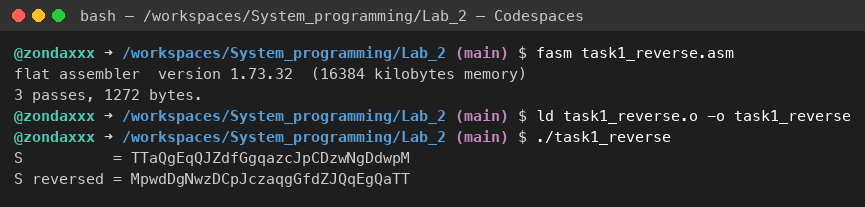

Сборка и запуск программы задания 1: строка выведена в обратном порядке.

## Задание 2. Заполнение памяти N символами и вывод матрицы M × K

В секции `.bss` резервируется область `buf` из N = 300 байт. В цикле `.fill` она заполняется символом `;`. Затем K = 25 раз выводится по M = 12 байт из памяти: подпрограмма `print` выводит `rdx` байт с адреса `rsi`, после каждой строки `newline` выводит перевод строки, а `rsi` сдвигается на M байт.

In [ ]:
%%writefile task2_matrix.asm
; Лабораторная работа №2. Задание 2. Вариант 16.
; Заполнить память N заданными символами и вывести их
; в виде матрицы по M символов в строке, K строк.
format ELF64
public _start

N = 300                           ; количество символов
M = 12                            ; символов в строке
K = 25                            ; количество строк
D = ';'                           ; заданный символ

section '.bss' writable
  buf db N dup (?)                ; область памяти под N символов

section '.data' writable
  nl db 0xA

section '.text' executable
_start:
    ; заполняем память N символами D
    mov rdi, buf
    mov rcx, N
    mov al, D
  .fill:
    mov [rdi], al
    inc rdi
    dec rcx
    jnz .fill

    ; выводим K строк по M символов
    mov rsi, buf                  ; текущая позиция в памяти
    mov rcx, K                    ; счетчик строк
  .row:
    mov rdx, M
    call print                    ; M символов текущей строки
    call newline
    add rsi, M                    ; переходим к следующей порции памяти
    dec rcx
    jnz .row
    call exit

section '.print' executable
; вывод на экран rdx байт, начиная с адреса rsi
print:
    push rax
    push rbx
    push rcx
    mov eax, 4                    ; sys_write
    mov ebx, 1                    ; stdout
    mov ecx, esi
    int 0x80
    pop rcx
    pop rbx
    pop rax
    ret

; вывод перевода строки
newline:
    push rsi
    push rdx
    mov rsi, nl
    mov rdx, 1
    call print
    pop rdx
    pop rsi
    ret

section '.exit' executable
exit:
    mov eax, 1                    ; sys_exit
    mov ebx, 0
    int 0x80


In [ ]:
!fasm task2_matrix.asm && ld task2_matrix.o -o task2_matrix && ./task2_matrix

flat assembler  version 1.73.32  (16384 kilobytes memory)
3 passes, 1224 bytes.
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;


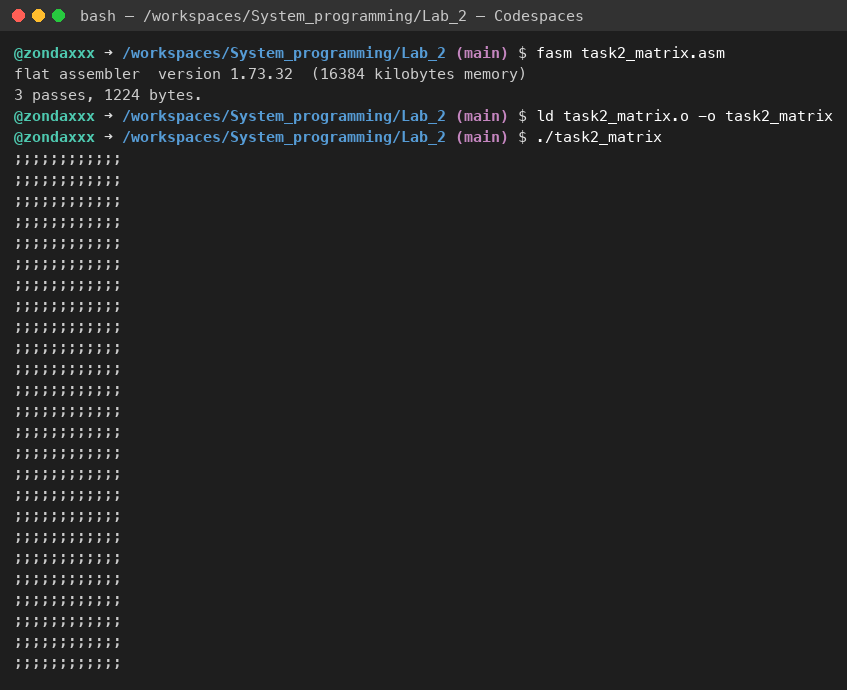

Сборка и запуск программы задания 2: матрица 25 строк по 12 символов.

In [ ]:
!./task2_matrix | wc -l
!./task2_matrix | head -1 | tr -d '\n' | wc -c
!./task2_matrix | tr -d '\n' | wc -c

25
12
300


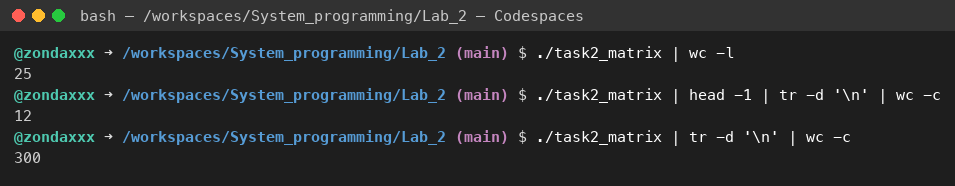

Проверка: 25 строк, 12 символов в строке, всего 300 символов.

## Задание 3. Вывод символов в виде треугольника

Заполнение памяти то же, что в задании 2. Длина строки хранится в `rcx` и начинается с 1; после вывода очередной строки указатель `rsi` сдвигается на выведенное количество байт, а `rcx` увеличивается на 1. Цикл продолжается, пока `rsi` не дойдёт до конца области (`cmp rsi, buf + N`), то есть пока не выведены все N символов. Для N = 300 получается 24 строки, так как 1 + 2 + … + 24 = 300.

In [ ]:
%%writefile task3_triangle.asm
; Лабораторная работа №2. Задание 3. Вариант 16.
; Заполнить память N заданными символами и вывести их в виде треугольника:
; в первой строке 1 символ, во второй 2 и т.д., пока не выведены все N символов.
format ELF64
public _start

N = 300                           ; количество символов (1+2+...+24 = 300)
D = ';'                           ; заданный символ

section '.bss' writable
  buf db N dup (?)

section '.data' writable
  nl db 0xA

section '.text' executable
_start:
    ; заполняем память N символами D
    mov rdi, buf
    mov rcx, N
    mov al, D
  .fill:
    mov [rdi], al
    inc rdi
    dec rcx
    jnz .fill

    ; выводим треугольник
    mov rsi, buf                  ; текущая позиция в памяти
    mov rcx, 1                    ; длина текущей строки
  .row:
    mov rdx, rcx
    call print                    ; rcx символов из памяти
    call newline
    add rsi, rcx                  ; сдвигаем позицию на выведенное количество
    inc rcx                       ; следующая строка длиннее на 1
    cmp rsi, buf + N              ; пока не выведены все N символов
    jb .row
    call exit

section '.print' executable
; вывод на экран rdx байт, начиная с адреса rsi
print:
    push rax
    push rbx
    push rcx
    mov eax, 4                    ; sys_write
    mov ebx, 1                    ; stdout
    mov ecx, esi
    int 0x80
    pop rcx
    pop rbx
    pop rax
    ret

; вывод перевода строки
newline:
    push rsi
    push rdx
    mov rsi, nl
    mov rdx, 1
    call print
    pop rdx
    pop rsi
    ret

section '.exit' executable
exit:
    mov eax, 1                    ; sys_exit
    mov ebx, 0
    int 0x80


In [ ]:
!fasm task3_triangle.asm && ld task3_triangle.o -o task3_triangle && ./task3_triangle

flat assembler  version 1.73.32  (16384 kilobytes memory)
3 passes, 1248 bytes.
;
;;
;;;
;;;;
;;;;;
;;;;;;
;;;;;;;
;;;;;;;;
;;;;;;;;;
;;;;;;;;;;
;;;;;;;;;;;
;;;;;;;;;;;;
;;;;;;;;;;;;;
;;;;;;;;;;;;;;
;;;;;;;;;;;;;;;
;;;;;;;;;;;;;;;;
;;;;;;;;;;;;;;;;;
;;;;;;;;;;;;;;;;;;
;;;;;;;;;;;;;;;;;;;
;;;;;;;;;;;;;;;;;;;;
;;;;;;;;;;;;;;;;;;;;;
;;;;;;;;;;;;;;;;;;;;;;
;;;;;;;;;;;;;;;;;;;;;;;
;;;;;;;;;;;;;;;;;;;;;;;;


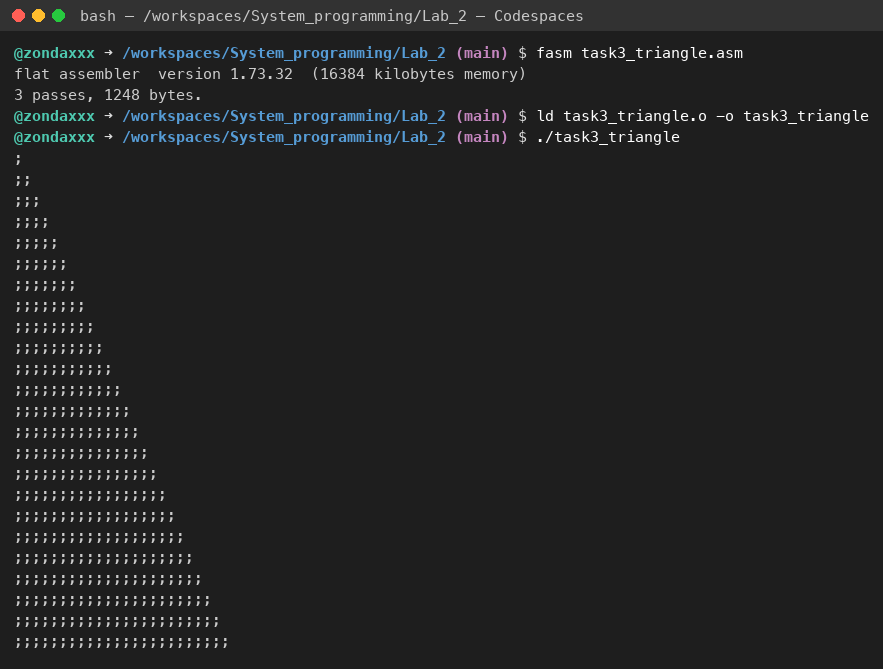

Сборка и запуск программы задания 3: треугольник из 300 символов.

In [ ]:
!./task3_triangle | wc -l
!./task3_triangle | tr -d '\n' | wc -c

24
300


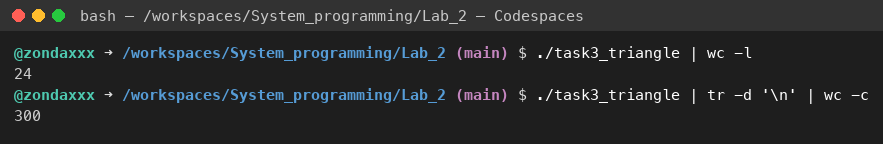

Проверка: 24 строки, всего 300 символов.

## Задание 4. Сумма цифр числа N

Число N = 2710058798 не помещается в 32 бита, поэтому хранится как `dq` и обрабатывается в 64-разрядных регистрах. В цикле `.digits` число делится на 10 командой `div rcx`: остаток в `rdx` — очередная цифра, она прибавляется к сумме в `rbx`; частное остаётся в `rax`, цикл идёт до тех пор, пока оно не станет нулём. Вывод суммы сделан по образцу примера 3 лекции 2: цифры результата помещаются в стек, затем извлекаются в обратном порядке и печатаются подпрограммой `print_symb`.

Проверка: 2 + 7 + 1 + 0 + 0 + 5 + 8 + 7 + 9 + 8 = 47.

In [ ]:
%%writefile task4_digit_sum.asm
; Лабораторная работа №2. Задание 4. Вариант 16.
; Для заданного числа N найти сумму его цифр и вывести результат на экран.
format ELF64
public _start

section '.data' writable
  number dq 2710058798            ; заданное число N
  msg    db "Sum of digits of 2710058798 = "
  msg_len = $ - msg
  place  db ?                     ; байт для вывода одного символа

section '.text' executable
_start:
    mov rsi, msg
    mov rdx, msg_len
    call print

    ; считаем сумму цифр: делим число на 10, остаток - очередная цифра
    mov rax, [number]
    mov rcx, 10
    xor rbx, rbx                  ; rbx - накопитель суммы
  .digits:
    xor rdx, rdx
    div rcx                       ; rax = rax / 10, rdx = rax mod 10
    add rbx, rdx
    test rax, rax
    jnz .digits

    ; выводим сумму: цифры кладем в стек, затем печатаем в обратном порядке
    mov rax, rbx
    xor rbx, rbx                  ; rbx - количество цифр
  .push:
    xor rdx, rdx
    div rcx
    add rdx, '0'                  ; цифра -> символ
    push rdx
    inc rbx
    test rax, rax
    jnz .push
  .pop:
    pop rax
    call print_symb
    dec rbx
    jnz .pop
    mov rax, 0xA
    call print_symb
    call exit

section '.print' executable
; вывод на экран rdx байт, начиная с адреса rsi
print:
    push rax
    push rbx
    push rcx
    mov eax, 4                    ; sys_write
    mov ebx, 1                    ; stdout
    mov ecx, esi
    int 0x80
    pop rcx
    pop rbx
    pop rax
    ret

; вывод одного символа из al
print_symb:
    push rbx
    push rcx
    push rdx
    push rax
    mov [place], al
    mov eax, 4
    mov ebx, 1
    mov ecx, place
    mov edx, 1
    int 0x80
    pop rax
    pop rdx
    pop rcx
    pop rbx
    ret

section '.exit' executable
exit:
    mov eax, 1                    ; sys_exit
    mov ebx, 0
    int 0x80


In [ ]:
!fasm task4_digit_sum.asm && ld task4_digit_sum.o -o task4_digit_sum && ./task4_digit_sum

flat assembler  version 1.73.32  (16384 kilobytes memory)
3 passes, 1256 bytes.
Sum of digits of 2710058798 = 47


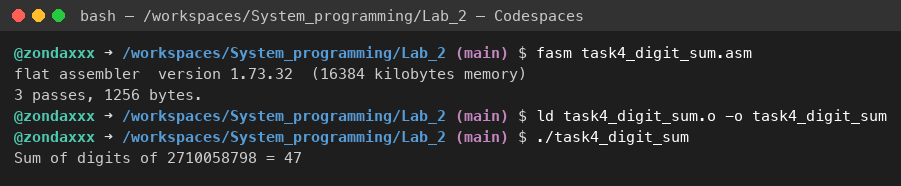

Сборка и запуск программы задания 4: сумма цифр равна 47.

## Задание 5. Программа на языке C и сравнение размеров исполняемых файлов

Та же задача на языке C. Число хранится в `unsigned long`, сумма цифр считается тем же способом — делением на 10.

In [ ]:
%%writefile task5_digit_sum.c
/* Лабораторная работа №2. Задание 5. Вариант 16.
   Сумма цифр числа N на языке C (обычная версия с использованием stdio). */
#include <stdio.h>

int main(void)
{
    unsigned long n = 2710058798UL;
    unsigned int sum = 0;
    while (n) {
        sum += n % 10;
        n /= 10;
    }
    printf("Sum of digits of 2710058798 = %u\n", sum);
    return 0;
}


In [ ]:
!gcc task5_digit_sum.c -o task5_digit_sum && ./task5_digit_sum
!ls -l task4_digit_sum task5_digit_sum

Sum of digits of 2710058798 = 47
-rwxrwxrwx 1 codespace codespace  8944 Sep 25 06:48 task4_digit_sum
-rwxrwxrwx 1 codespace codespace 15976 Sep 25 06:48 task5_digit_sum


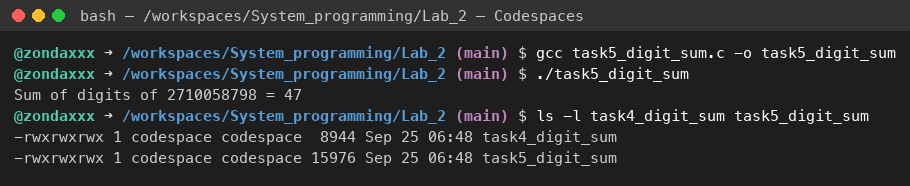

Компиляция и запуск программы на C, сравнение с ассемблерной версией.

### Сравнение размеров

| Файл | Язык | Сборка | Размер, байт |
|---|---|---|---|
| `task5_digit_sum` | C | `gcc` по умолчанию | 15 976 |
| `task4_digit_sum` | asm | `fasm` + `ld` | 8 944 |

Программа на C почти вдвое больше. Причины: динамическая компоновка с libc (таблицы `.dynamic`, `.plt`, `.got`, интерпретатор), стартовый код `crt1.o`/`crti.o`, таблицы раскрутки стека `.eh_frame`, секции `.note`, таблица символов, а также сборка в виде PIE. Ассемблерная программа содержит только свой код и данные, но тоже занимает 8,9 КБ: компоновщик по умолчанию выравнивает каждую загружаемую секцию на границу страницы 4096 байт, а в программе пять секций.

### Сокращение размера программы на C

**Шаг 1.** Оптимизация по размеру и удаление таблицы символов: `gcc -Os -s`.

**Шаг 2.** Отказ от стандартной библиотеки и стартового кода: точка входа `_start` пишется самостоятельно, системные вызовы `write` и `exit` выполняются напрямую инструкцией `syscall` через встроенный ассемблер, вывод числа делается вручную в буфер. Ключи: `-nostdlib -static` (нет libc и динамического загрузчика), `-fno-asynchronous-unwind-tables` (нет `.eh_frame`), `-fno-stack-protector`, `-Wl,--gc-sections` (удалить неиспользуемые секции), `-Wl,--build-id=none` (нет секции `.note.gnu.build-id`), `-Wl,-N` (не выравнивать секции на страницы).

In [ ]:
%%writefile task5_min.c
/* Лабораторная работа №2. Задание 5. Вариант 16.
   Минимизированная версия на C: без libc и стартового кода,
   системные вызовы делаются напрямую через инструкцию syscall.
   Сборка:
   gcc -Os -s -static -nostdlib -fno-asynchronous-unwind-tables -fno-stack-protector \
       -Wl,--gc-sections -Wl,--build-id=none -Wl,-N task5_min.c -o task5_min_c */

static void sys_write(const char *buf, unsigned long len)
{
    __asm__ volatile ("syscall"
                      : : "a"(1), "D"(1), "S"(buf), "d"(len)
                      : "rcx", "r11", "memory");
}

static void sys_exit(void)
{
    __asm__ volatile ("syscall" : : "a"(60), "D"(0));
    __builtin_unreachable();
}

void _start(void)
{
    unsigned long n = 2710058798UL;
    unsigned int sum = 0;
    char buf[12];
    int i = sizeof buf;

    while (n) {
        sum += n % 10;
        n /= 10;
    }
    buf[--i] = '\n';
    do {
        buf[--i] = '0' + sum % 10;
        sum /= 10;
    } while (sum);
    sys_write(buf + i, sizeof buf - i);
    sys_exit();
}


### Сокращение размера программы на ассемблере

**Шаг 1.** Удаление таблицы символов: `strip`. Выигрыш небольшой, потому что основной объём — выравнивание секций.

**Шаг 2.** Компоновка с ключами `ld -N -s`: `-N` отключает выравнивание секций на страницы и делает сегмент кода записываемым, `-s` убирает символы. Файл уменьшается с 8 944 до 776 байт.

**Шаг 3.** Полный отказ от компоновщика: `format ELF64 executable` — fasm сам формирует готовый исполняемый файл с минимальным заголовком и одним сегментом. Сообщение убрано, выводится только результат, буфер под строку размещён в стеке (поэтому используется 64-битный системный вызов `syscall` — адреса стека не помещаются в 32-битный `ecx`, нужный для `int 0x80`).

**Шаг 4.** 32-разрядная версия `format ELF executable`: заголовки ELF32 короче, чем ELF64, число 2710058798 < 2³² помещается в 32-битный регистр, а стек в 32-битном процессе адресуется через `ecx`, поэтому снова можно использовать `int 0x80`.

In [ ]:
%%writefile task5_min64.asm
; Лабораторная работа №2. Задание 5. Вариант 16.
; Минимизированная 64-битная версия: fasm сам формирует исполняемый ELF
; (без секций, без линковщика), буфер для строки - в стеке (red zone),
; поэтому используется 64-битный системный вызов syscall.
format ELF64 executable 3
entry start

segment readable executable
start:
    mov rax, 2710058798           ; заданное число N
    mov ecx, 10
    xor ebx, ebx                  ; ebx - сумма цифр
  .digits:
    xor edx, edx
    div rcx
    add ebx, edx
    test rax, rax
    jnz .digits

    ; переводим сумму в строку, заполняя буфер с конца
    mov eax, ebx
    lea rsi, [rsp - 1]
    mov byte [rsi], 0xA
  .conv:
    xor edx, edx
    div ecx
    add dl, '0'
    dec rsi
    mov [rsi], dl
    test eax, eax
    jnz .conv

    mov rdx, rsp                  ; длина строки = rsp - rsi
    sub rdx, rsi
    mov edi, 1                    ; stdout
    mov eax, 1                    ; sys_write (64-битный ABI)
    syscall
    mov eax, 60                   ; sys_exit
    xor edi, edi
    syscall


In [ ]:
%%writefile task5_min32.asm
; Лабораторная работа №2. Задание 5. Вариант 16.
; Минимизированная 32-битная версия: заголовки ELF32 короче, чем у ELF64,
; число 2710058798 < 2^32 и помещается в 32-битный регистр.
format ELF executable 3
entry start

segment readable executable
start:
    mov eax, 2710058798           ; заданное число N
    mov ecx, 10
    xor ebx, ebx                  ; ebx - сумма цифр
  .digits:
    xor edx, edx
    div ecx
    add ebx, edx
    test eax, eax
    jnz .digits

    ; переводим сумму в строку в буфере на стеке
    sub esp, 16
    mov eax, ebx
    lea esi, [esp + 15]
    mov byte [esi], 0xA
  .conv:
    xor edx, edx
    div ecx
    add dl, '0'
    dec esi
    mov [esi], dl
    test eax, eax
    jnz .conv

    lea edx, [esp + 16]           ; длина строки = esp + 16 - esi
    sub edx, esi
    mov ecx, esi
    mov ebx, 1                    ; stdout
    mov eax, 4                    ; sys_write
    int 0x80
    mov eax, 1                    ; sys_exit
    xor ebx, ebx
    int 0x80


In [ ]:
!gcc -Os -s task5_digit_sum.c -o task5_digit_sum_Os
!gcc -Os -s -static -nostdlib -fno-asynchronous-unwind-tables -fno-stack-protector -Wl,--gc-sections -Wl,--build-id=none -Wl,-N task5_min.c -o task5_min_c && ./task5_min_c
!strip -o task4_digit_sum_stripped task4_digit_sum && ./task4_digit_sum_stripped
!fasm task5_min64.asm task5_min64 && chmod +x task5_min64 && ./task5_min64
!fasm task5_min32.asm task5_min32 && chmod +x task5_min32 && ./task5_min32
!ls -l task4_digit_sum task4_digit_sum_stripped task5_min64 task5_min32 task5_digit_sum task5_digit_sum_Os task5_min_c

/usr/bin/ld: warning: task5_min_c has a LOAD segment with RWX permissions
47
Sum of digits of 2710058798 = 47
flat assembler  version 1.73.32  (16384 kilobytes memory)
2 passes, 202 bytes.
47
flat assembler  version 1.73.32  (16384 kilobytes memory)
2 passes, 161 bytes.
47
-rwxrwxrwx 1 codespace codespace  8944 Sep 25 06:48 task4_digit_sum
-rwxrwxrwx 1 codespace codespace  8656 Sep 25 06:48 task4_digit_sum_stripped
-rwxrwxrwx 1 codespace codespace 15976 Sep 25 06:48 task5_digit_sum
-rwxrwxrwx 1 codespace codespace 14472 Sep 25 06:48 task5_digit_sum_Os
-rwxrwxrwx 1 codespace codespace   161 Sep 25 06:48 task5_min32
-rwxrwxrwx 1 codespace codespace   202 Sep 25 06:48 task5_min64
-rwxrwxrwx 1 codespace codespace   848 Sep 25 06:48 task5_min_c


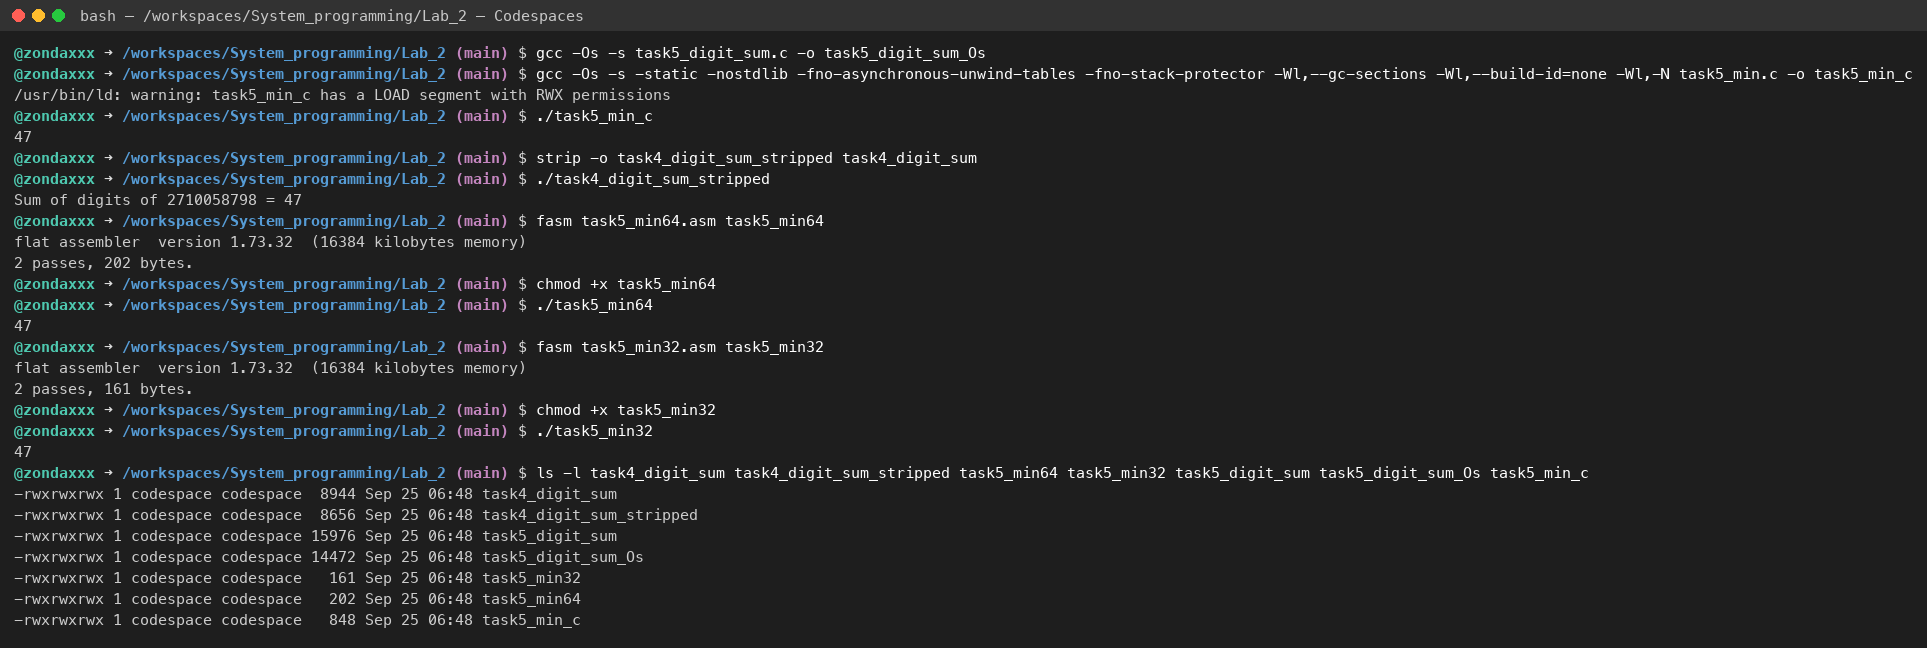

Сборка и запуск сокращённых версий, все выводят 47.

In [ ]:
!ld -N -s task4_digit_sum.o -o task4_digit_sum_N && ./task4_digit_sum_N
!ls -l task4_digit_sum task4_digit_sum_stripped task4_digit_sum_N

ld: warning: task4_digit_sum_N has a LOAD segment with RWX permissions
Sum of digits of 2710058798 = 47
-rwxrwxrwx 1 codespace codespace 8944 Sep 25 06:48 task4_digit_sum
-rwxrwxrwx 1 codespace codespace  776 Sep 25 06:49 task4_digit_sum_N
-rwxrwxrwx 1 codespace codespace 8656 Sep 25 06:48 task4_digit_sum_stripped


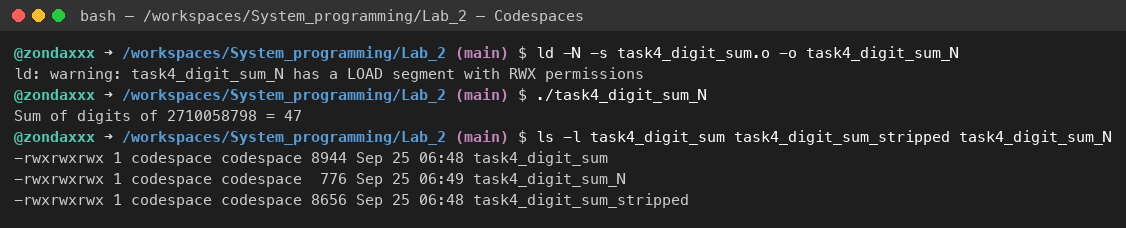

Компоновка ассемблерной программы с ключами -N -s.

In [ ]:
!file task5_digit_sum task5_min_c task5_min64 task5_min32

task5_digit_sum: ELF 64-bit LSB pie executable, x86-64, version 1 (SYSV), dynamically linked, interpreter /lib64/ld-linux-x86-64.so.2, BuildID[sha1]=67910978b4bb90c3504da17105a732326cbaa850, for GNU/Linux 3.2.0, not stripped
task5_min_c:     ELF 64-bit LSB executable, x86-64, version 1 (SYSV), statically linked, stripped
task5_min64:     ELF 64-bit LSB executable, x86-64, version 1 (GNU/Linux), statically linked, no section header
task5_min32:     ELF 32-bit LSB executable, Intel 80386, version 1 (GNU/Linux), statically linked, no section header


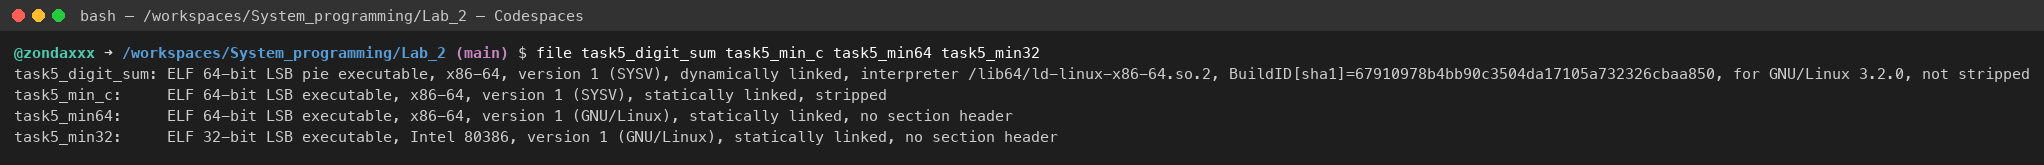

Типы полученных файлов: у минимальных версий нет даже таблицы секций.

### Итоговая таблица размеров

| Файл | Язык | Способ сборки | Размер, байт |
|---|---|---|---|
| `task5_digit_sum` | C | `gcc` | 15 976 |
| `task5_digit_sum_Os` | C | `gcc -Os -s` | 14 472 |
| `task5_min_c` | C | без libc: `-nostdlib -static -Wl,-N …` | 848 |
| `task4_digit_sum` | asm | `fasm` + `ld` | 8 944 |
| `task4_digit_sum_stripped` | asm | `fasm` + `ld` + `strip` | 8 656 |
| `task4_digit_sum_N` | asm | `fasm` + `ld -N -s` | 776 |
| `task5_min64` | asm | `format ELF64 executable`, без `ld` | 202 |
| `task5_min32` | asm | `format ELF executable` (32 бит), без `ld` | 161 |

**Выводы.**

1. Обычные ключи оптимизации (`-Os -s`) почти не уменьшают программу на C: основной объём занимает не код, а инфраструктура динамической компоновки и стартовый код libc.
2. Отказ от libc сокращает программу на C в 19 раз (до 848 байт), но она всё равно больше ассемблерной, потому что gcc и ld добавляют служебные заголовки и таблицу секций.
3. Для ассемблерной программы главный резерв — выравнивание секций компоновщиком: ключ `-N` уменьшает файл в 11 раз.
4. Минимальный размер даёт прямое формирование ELF ассемблером fasm: 202 байта для 64-разрядной и 161 байт для 32-разрядной версии, из которых большая часть — заголовок ELF (64 + 56 байт для ELF64, 52 + 32 байта для ELF32).
5. Итоговое сокращение: C — с 15 976 до 848 байт, ассемблер — с 8 944 до 161 байта; все версии выводят одинаковый результат 47.

## Сборка всего проекта

Скрипт `build.sh` собирает все задания и печатает таблицу размеров.

In [ ]:
%%writefile build.sh
#!/bin/bash
# Лабораторная работа №2. Сборка всех заданий и сравнение размеров файлов.
set -e
cd "$(dirname "$0")"

# Задания 1-4: fasm -> объектный файл -> ld -> исполняемый файл
for t in task1_reverse task2_matrix task3_triangle task4_digit_sum; do
    fasm "$t.asm" > /dev/null
    ld "$t.o" -o "$t"
done

# Задание 5: обычная версия на C
gcc task5_digit_sum.c -o task5_digit_sum

# Задание 5: сокращение размера
# C: оптимизация по размеру + удаление символов
gcc -Os -s task5_digit_sum.c -o task5_digit_sum_Os
# C: без libc, без стартового кода, прямые системные вызовы
gcc -Os -s -static -nostdlib -fno-asynchronous-unwind-tables -fno-stack-protector \
    -Wl,--gc-sections -Wl,--build-id=none -Wl,-N task5_min.c -o task5_min_c
# asm: удаление таблицы символов из обычной версии
strip -o task4_digit_sum_stripped task4_digit_sum
# asm: компоновка без выравнивания секций на страницы (-N) и без символов (-s)
ld -N -s task4_digit_sum.o -o task4_digit_sum_N
# asm: fasm сразу формирует исполняемый ELF без линковщика
fasm task5_min64.asm task5_min64 > /dev/null
fasm task5_min32.asm task5_min32 > /dev/null
chmod +x task5_min64 task5_min32

echo "Размеры исполняемых файлов (байт):"
ls -l task4_digit_sum task4_digit_sum_stripped task4_digit_sum_N task5_min64 task5_min32 \
      task5_digit_sum task5_digit_sum_Os task5_min_c | awk '{printf "%8d  %s\n", $5, $9}'


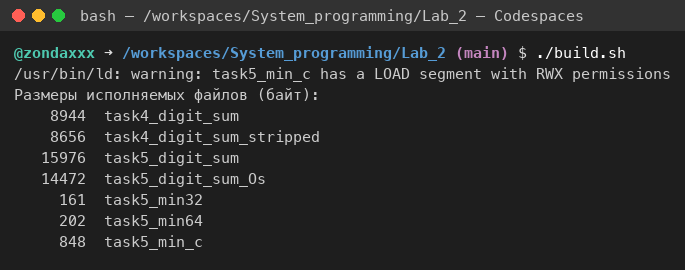

Запуск скрипта сборки.